✅ Saved → optimizer_comparison.png

Final loss after 60 steps:
  SGD         0.186418
  Momentum    0.025567
  RMSprop     0.025518
  Adam        0.054398


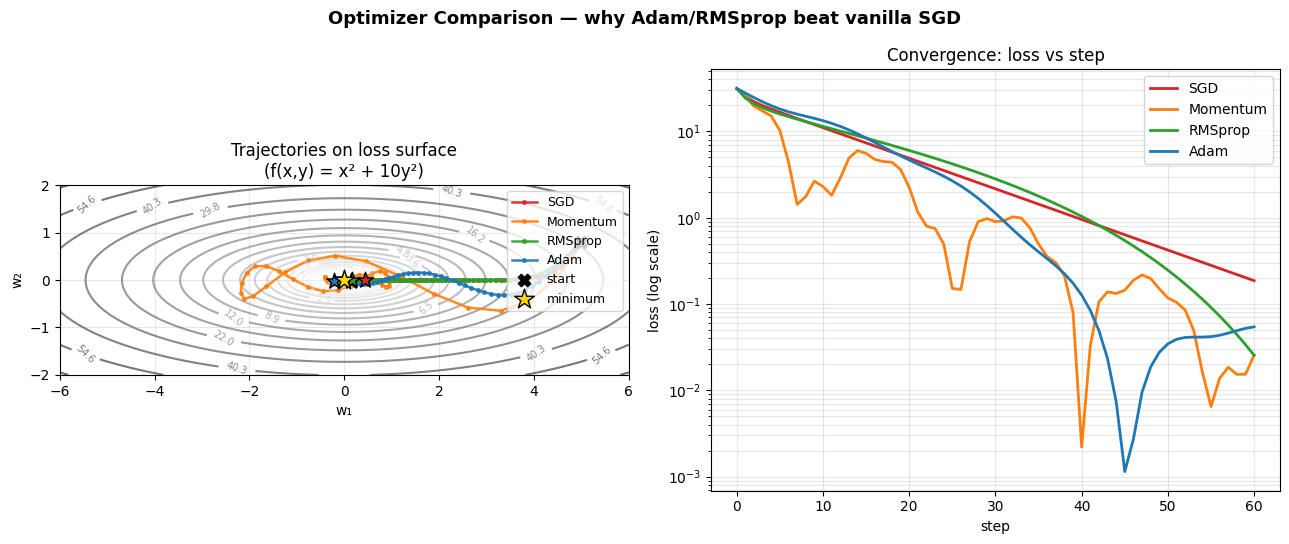

In [1]:
"""
optimizer_comparison.py
========================
Visual comparison of gradient descent optimizers.

We optimize an ILL-CONDITIONED quadratic:
    f(x, y) = x² + 10y²

The curvature differs 10x along the two axes. This creates a narrow
"ravine" — vanilla SGD zigzags and crawls, while momentum-based and
adaptive optimizers navigate it efficiently.

Optimizers compared:
    - SGD       : w ← w − lr·∇L
    - Momentum  : v ← β·v + ∇L        ;  w ← w − lr·v
    - RMSprop   : s ← β·s + (1−β)·g²  ;  w ← w − lr·g/√(s+ε)
    - Adam      : momentum (m) + RMSprop (v) with bias correction

Run:     python optimizer_comparison.py
Output:  optimizer_comparison.png
"""

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm


# ===================================================================
# 1. LOSS LANDSCAPE
# ===================================================================
def loss(w):
    """f(x, y) = x² + 10y²  — curvature differs 10x between axes"""
    x, y = w
    return x**2 + 10 * y**2


def grad(w):
    """∇f = [2x, 20y]"""
    x, y = w
    return np.array([2.0 * x, 20.0 * y])


# ===================================================================
# 2. OPTIMIZERS (from scratch — so you can see the math!)
# ===================================================================
class SGD:
    """Vanilla gradient descent:  w ← w − lr·∇L"""
    def __init__(self, w0, lr=0.02):
        self.w, self.lr = w0.copy(), lr

    def step(self, g):
        self.w -= self.lr * g
        return self.w


class Momentum:
    """
    Accumulates a velocity in the direction of persistent gradients.
    Directions that keep changing (zigzag) cancel out.
        v ← β·v + g
        w ← w − lr·v
    """
    def __init__(self, w0, lr=0.02, beta=0.9):
        self.w = w0.copy()
        self.v = np.zeros_like(w0)
        self.lr, self.beta = lr, beta

    def step(self, g):
        self.v = self.beta * self.v + g
        self.w -= self.lr * self.v
        return self.w


class RMSprop:
    """
    Adaptive per-parameter learning rate. Divides gradient by running RMS
    of recent gradients → big gradients get shrunk, small ones get boosted.
    This handles ill-conditioning automatically.
        s ← β·s + (1−β)·g²
        w ← w − lr·g / (√s + ε)
    """
    def __init__(self, w0, lr=0.1, beta=0.9, eps=1e-8):
        self.w = w0.copy()
        self.s = np.zeros_like(w0)
        self.lr, self.beta, self.eps = lr, beta, eps

    def step(self, g):
        self.s = self.beta * self.s + (1 - self.beta) * g**2
        self.w -= self.lr * g / (np.sqrt(self.s) + self.eps)
        return self.w


class Adam:
    """
    Momentum + RMSprop combined, with bias correction.
        m ← β1·m + (1−β1)·g
        v ← β2·v + (1−β2)·g²
        m̂ = m / (1−β1ᵗ)   v̂ = v / (1−β2ᵗ)   ← bias correction
        w ← w − lr·m̂ / (√v̂ + ε)
    """
    def __init__(self, w0, lr=0.15, beta1=0.9, beta2=0.999, eps=1e-8):
        self.w = w0.copy()
        self.m = np.zeros_like(w0)
        self.v = np.zeros_like(w0)
        self.lr = lr
        self.beta1, self.beta2, self.eps = beta1, beta2, eps
        self.t = 0

    def step(self, g):
        self.t += 1
        self.m = self.beta1 * self.m + (1 - self.beta1) * g
        self.v = self.beta2 * self.v + (1 - self.beta2) * g**2
        m_hat = self.m / (1 - self.beta1 ** self.t)
        v_hat = self.v / (1 - self.beta2 ** self.t)
        self.w -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)
        return self.w


# ===================================================================
# 3. TRAINING LOOP
# ===================================================================
def train(opt_class, w0, steps=60, **kwargs):
    opt = opt_class(w0, **kwargs)
    path = [opt.w.copy()]
    losses = [loss(opt.w)]
    for _ in range(steps):
        g = grad(opt.w)
        w = opt.step(g)
        path.append(w.copy())
        losses.append(loss(w))
    return np.array(path), np.array(losses)


# ===================================================================
# 4. PLOT
# ===================================================================
def main():
    w0 = np.array([5.0, 0.8])   # start far from minimum
    steps = 60

    configs = {
        'SGD':       (SGD,      {'lr': 0.02}),
        'Momentum':  (Momentum, {'lr': 0.02, 'beta': 0.9}),
        'RMSprop':   (RMSprop,  {'lr': 0.10, 'beta': 0.9}),
        'Adam':      (Adam,     {'lr': 0.15}),
    }
    colors = {'SGD': 'tab:red', 'Momentum': 'tab:orange',
              'RMSprop': 'tab:green', 'Adam': 'tab:blue'}

    # ---- run all optimizers ----
    results = {}
    for name, (cls, kw) in configs.items():
        path, losses = train(cls, w0, steps=steps, **kw)
        results[name] = (path, losses)

    # ---- two-panel figure ----
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))

    # --- panel 1: contour + trajectories ---
    xs = np.linspace(-6, 6, 300)
    ys = np.linspace(-2, 2, 300)
    X, Y = np.meshgrid(xs, ys)
    Z = X**2 + 10 * Y**2

    cs = ax1.contour(X, Y, Z, levels=np.logspace(-0.5, 2, 20),
                     cmap='Greys', norm=LogNorm(), alpha=0.6)
    ax1.clabel(cs, inline=True, fontsize=7, fmt='%.1f')

    for name, (path, _) in results.items():
        ax1.plot(path[:, 0], path[:, 1], '-o', color=colors[name],
                 markersize=2.5, linewidth=1.8, alpha=0.9, label=name)
        ax1.scatter(path[-1, 0], path[-1, 1], color=colors[name],
                    s=140, marker='*', edgecolor='black', zorder=5)

    ax1.scatter(*w0, color='black', s=80, marker='X',
                zorder=5, label='start')
    ax1.scatter(0, 0, color='gold', s=220, marker='*',
                edgecolor='black', zorder=5, label='minimum')
    ax1.set_xlabel('w₁')
    ax1.set_ylabel('w₂')
    ax1.set_title('Trajectories on loss surface\n(f(x,y) = x² + 10y²)')
    ax1.legend(loc='upper right', fontsize=9)
    ax1.grid(True, alpha=0.3)
    ax1.set_aspect('equal')

    # --- panel 2: loss curves ---
    for name, (_, losses) in results.items():
        ax2.plot(losses, color=colors[name], linewidth=2, label=name)
    ax2.set_yscale('log')
    ax2.set_xlabel('step')
    ax2.set_ylabel('loss (log scale)')
    ax2.set_title('Convergence: loss vs step')
    ax2.legend()
    ax2.grid(True, which='both', alpha=0.3)

    fig.suptitle('Optimizer Comparison — why Adam/RMSprop beat vanilla SGD',
                 fontsize=13, fontweight='bold')
    fig.tight_layout()
    fig.savefig('optimizer_comparison.png', dpi=150, bbox_inches='tight')
    print('✅ Saved → optimizer_comparison.png\n')

    # ---- summary ----
    print(f'Final loss after {steps} steps:')
    for name, (_, losses) in results.items():
        print(f'  {name:10s}  {losses[-1]:.6f}')


if __name__ == '__main__':
    main()